In [1]:
import sys, time, warnings
warnings.filterwarnings("ignore", message="The number of unique classes")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, networkx as nx
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from scipy import stats
from sklearn.metrics import normalized_mutual_info_score as NMI, adjusted_mutual_info_score as AMI, adjusted_rand_score as ARI

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(ROOT), str(ROOT / "nlp" / "scripts")]
import network_tools as nt
import community_tools as ct
from distinctive_words import distinctive_words

OUT = ROOT / "results" / "communities"
OUT.mkdir(parents=True, exist_ok=True)
N_PERM = 999          # label permutations (coherence, beyond-genre)
N_SIL_PERM = 100      # permutations for the silhouette null
N_REWIRED = 100       # A's rewired networks in network/null/
MIN_SIZE = 40         # communities shown in Fig. 3 / the statistics table
SIMS = ["tfidf", "embed"]
pd.set_option("display.precision", 3); pd.set_option("display.width", 160)

# colours: categorical slots 1-3 + neutral grey for nulls; diverging blue <-> red with grey midpoint
C1, C2, C3, C_NULL = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a85"
DIVERGING = LinearSegmentedColormap.from_list("div", ["#184f95", "#6da7ec", "#f0efec", "#ef8f8e", "#a8302f"])
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "font.size": 9})

## 0. Data

In [ ]:
nodes = nt.load_nodes()
n = len(nodes)
title = nodes.name.to_numpy()
parts = ct.load_partitions()
cons = pd.read_csv(ROOT / "communities" / "consensus.tsv", sep="\t", comment="#") # consensus partition
S = {k: ct.load_similarity(k, nodes) for k in SIMS}
G = {s: ct.scheme_graph(s, nodes) for s in ct.SCHEMES}
W0 = nx.to_numpy_array(G["default"], nodelist=range(n))
L = {s: ct.labels_of(cons, nodes, scheme=s) for s in ct.SCHEMES}          # consensus labels per scheme
L0 = L["default"]
RUNS = {s: np.stack([ct.labels_of(parts, nodes, scheme=s, seed=k) for k in range(ct.N_SEEDS)]) for s in ct.SCHEMES}
gcount = pd.Series([g for s in nodes.genre_set for g in s]).value_counts()
PG = ct.primary_genre(nodes, gcount)
print(f"{n} films, {W0.astype(bool).sum() // 2} edges (default scheme), {len(ct.SCHEMES)} schemes x {ct.N_SEEDS} seeds")
print("primary genre (rarest of the film's IMDb genres):", pd.Series(PG).value_counts().to_dict())

1744 films, 11465 edges (default scheme), 8 schemes x 50 seeds
primary genre (rarest of the film's IMDb genres): {'Mystery': 207, 'Romance': 207, 'Adventure': 149, 'Sci-Fi': 137, 'Biography': 130, 'Thriller': 129, 'Crime': 127, 'Fantasy': 127, 'Comedy': 118, 'Horror': 95, 'Family': 72, 'History': 68, 'Drama': 48, 'Music': 40, 'Sport': 27, 'War': 24, 'Western': 14, 'Action': 14, 'Musical': 7, 'Documentary': 4}


## 1. Community detection and stability (SQ3)

Weighted Louvain (networkx `louvain_communities`, resolution 1), 50 seeds per scheme.
*Stability* = mean NMI over all 1225 pairs of seeds. The **consensus partition** (Lancichinetti & Fortunato 2012)
clusters the co-assignment matrix of the 50 runs (threshold 0.5) until all runs agree; it is the partition used in
the rest of the notebook. Isolated films (84 in `default`) are singleton communities.

In [3]:
rows = []
for s in ct.SCHEMES:
    q = np.array([ct.modularity(G[s], lab) for lab in RUNS[s]])
    nmi = ct.pairwise_scores(list(RUNS[s]))
    sizes = np.bincount(L[s])
    rows.append({"scheme": s, "edges": G[s].number_of_edges(), "communities": len(sizes),
                 "communities >= 5 films": int((sizes >= 5).sum()), "largest": int(sizes.max()),
                 "Q mean (seeds)": q.mean(), "Q sd": q.std(ddof=1), "Q consensus": ct.modularity(G[s], L[s]),
                 "NMI seeds mean": nmi.mean(), "NMI seeds min": nmi.min(),
                 "NMI consensus vs seeds": np.mean([NMI(L[s], r) for r in RUNS[s]])})
stab = pd.DataFrame(rows).set_index("scheme")
stab.to_csv(OUT / "stability_by_scheme.csv")
stab

,edges,communities,communities >= 5 films,largest,Q mean (seeds),Q sd,Q consensus,NMI seeds mean,NMI seeds min,NMI consensus vs seeds
scheme,,,,,,,,,,
default,11465,129,31,130,0.530,1.503e-03,0.527,0.673,0.585,0.754
actors,10357,184,27,118,0.557,2.297e-03,0.556,0.666,0.601,0.741
directors,1102,1085,22,9,0.993,0.000e+00,0.993,1.000,1.000,1.000
dir1,11302,133,28,120,0.528,2.172e-03,0.530,0.625,0.555,0.716
dir2,11302,128,27,121,0.521,1.827e-03,0.523,0.655,0.580,0.744
dir4,11302,134,34,111,0.553,1.478e-03,0.552,0.703,0.615,0.783
dir10,11302,141,40,82,0.680,7.287e-04,0.679,0.792,0.727,0.844
billing,11302,125,31,123,0.575,1.428e-03,0.575,0.743,0.665,0.810


**Modularity against the degree-preserving null.** Louvain on each of A's 100 rewired versions of the `default`
network (same degrees and weight distribution, edges placed at random). If the observed Q is far above the
rewired Q, the community structure is not a by-product of the degree sequence.

Q observed (mean of 50 seeds) = 0.530;  rewired: 0.300 +- 0.002 (max 0.306);  z = 151.0


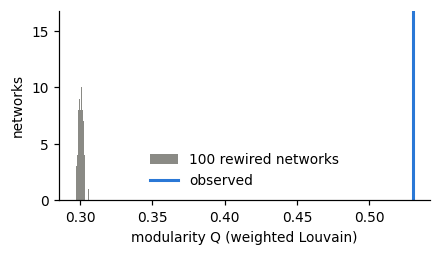

In [4]:
q_null = []
for k in range(N_REWIRED):
    e = nt.read_tsv(ROOT / "network" / "null" / f"rewired_{k}.tsv")
    Gr = nx.from_numpy_array(nt.weight_matrix(e, nodes))
    q_null.append(ct.modularity(Gr, ct.louvain(Gr, seed=k)))
q_null = np.array(q_null)
q_obs = stab.loc["default", "Q mean (seeds)"]
z_q = (q_obs - q_null.mean()) / q_null.std(ddof=1)
print(f"Q observed (mean of 50 seeds) = {q_obs:.3f};  rewired: {q_null.mean():.3f} +- {q_null.std(ddof=1):.3f} "
      f"(max {q_null.max():.3f});  z = {z_q:.1f}")

fig, ax = plt.subplots(figsize=(4.2, 2.4))
ax.hist(q_null, bins=20, color=C_NULL, label=f"{N_REWIRED} rewired networks")
ax.axvline(q_obs, color=C1, lw=2, label="observed")
ax.set_xlabel("modularity Q (weighted Louvain)"); ax.set_ylabel("networks"); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(OUT / "modularity_vs_rewired.pdf"); plt.show()

## 2. Semantic coherence of the communities (SQ3)

Mean plot similarity of film pairs **within** the same community vs. **between** communities. Null: shuffle
community labels over films (999 times), which keeps every community's size. Because within-community pairs are
often directly linked, we also repeat the comparison on **unlinked pairs only**: if communities still group
similar plots there, they capture more than the edges themselves (Theme A's linked-vs-unlinked result).

In [5]:
iu = np.triu_indices(n, 1)
unlinked = W0[iu] == 0

def within_between_pairs(s, lab, mask):
    same = lab[iu[0]][mask] == lab[iu[1]][mask]
    v = s[mask]
    return v[same].mean(), v[~same].mean()

rows = []
for kind in SIMS:
    t0 = time.time()
    res = ct.label_permutation_test(S[kind], L0, n_perm=N_PERM, seed=1)
    # unlinked-pairs version with the same kind of null
    s_up = S[kind][iu]
    w, b = within_between_pairs(s_up, L0, unlinked)
    rng = np.random.default_rng(2)
    null = np.array([np.subtract(*within_between_pairs(s_up, rng.permutation(L0), unlinked)) for _ in range(N_PERM)])
    rows.append({"similarity": kind, "pairs": "all", **res})
    rows.append({"similarity": kind, "pairs": "unlinked only", "within": w, "between": b, "diff": w - b,
                 "null_mean": null.mean(), "null_sd": null.std(ddof=1), "z": (w - b - null.mean()) / null.std(ddof=1),
                 "p": (1 + (null >= w - b).sum()) / (N_PERM + 1)})
    print(kind, f"{time.time() - t0:.0f}s")
coh = pd.DataFrame(rows)
coh["ratio within/between"] = coh.within / coh.between
coh.to_csv(OUT / "coherence_default.csv", index=False)
coh

tfidf 15s


embed 15s


,similarity,pairs,within,between,diff,null_mean,null_sd,z,p,ratio within/between
0,tfidf,all,0.029,0.029,5.432e-04,-9.910e-06,2.006e-04,2.757,0.001,1.019
1,tfidf,unlinked only,0.029,0.029,2.074e-04,7.528e-06,1.950e-04,1.025,0.158,1.007
2,embed,all,0.613,0.611,1.877e-03,-7.044e-05,1.817e-03,1.072,0.145,1.003
3,embed,unlinked only,0.611,0.611,-2.338e-05,6.343e-05,1.831e-03,-0.047,0.517,1.000


**Silhouette** on cosine distance 1 − *S* (films in communities of ≥ 5 films), against 100 size-preserving label
shuffles. Plot space is not expected to separate cleanly into these communities (silhouettes near 0 are normal for
text); the question is whether it is *above the shuffled value*.

In [6]:
sil = []
for kind in SIMS:
    obs, null = ct.silhouette(S[kind], L0, min_size=5, n_perm=N_SIL_PERM, seed=3)
    sil.append({"similarity": kind, "silhouette": obs, "null mean": null.mean(), "null sd": null.std(ddof=1),
                "z": (obs - null.mean()) / null.std(ddof=1), "p": (1 + (null >= obs).sum()) / (N_SIL_PERM + 1)})
sil = pd.DataFrame(sil); sil.to_csv(OUT / "silhouette_default.csv", index=False); sil

,similarity,silhouette,null mean,null sd,z,p
0,tfidf,-0.010,-0.010,8.856e-04,0.449,0.386
1,embed,-0.106,-0.107,2.713e-02,0.015,0.584


## 3. Across weighting schemes (SQ3)

Same Louvain + consensus on each of A's weighting schemes. (i) How similar are the partitions (NMI / ARI between
consensus partitions)? (ii) How coherent are they in plot space (z of within − between, embeddings)? (iii) How do
films move between communities when directors gain weight?

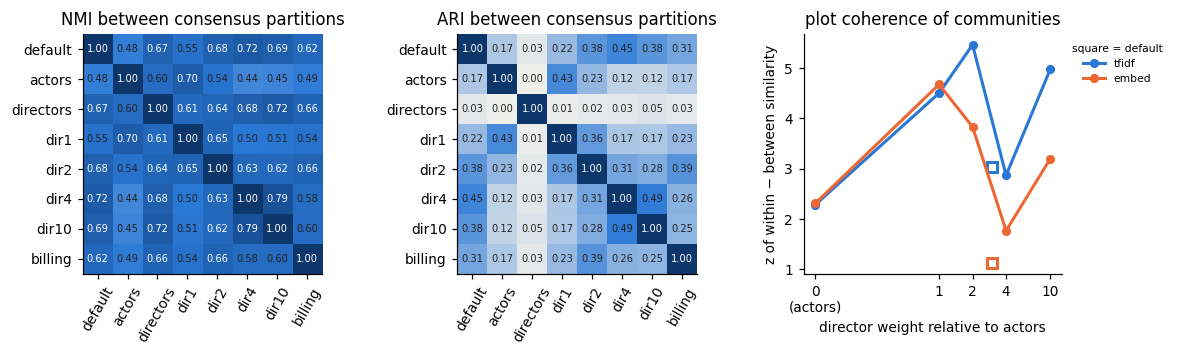

similarity,embed,tfidf
scheme,,
default,1.127,3.022
actors,2.309,2.282
directors,7.748,13.458
dir1,4.674,4.501
dir2,3.829,5.463
dir4,1.763,2.865
dir10,3.198,4.981
billing,2.655,5.154


In [7]:
nmi_m = pd.DataFrame([[NMI(L[a], L[b]) for b in ct.SCHEMES] for a in ct.SCHEMES], ct.SCHEMES, ct.SCHEMES)
ari_m = pd.DataFrame([[ARI(L[a], L[b]) for b in ct.SCHEMES] for a in ct.SCHEMES], ct.SCHEMES, ct.SCHEMES)
nmi_m.to_csv(OUT / "scheme_nmi.csv"); ari_m.to_csv(OUT / "scheme_ari.csv")

rows = []
for s in ct.SCHEMES:
    for kind in SIMS:
        r = ct.label_permutation_test(S[kind], L[s], n_perm=199, seed=4)
        rows.append({"scheme": s, "similarity": kind, "communities >= 5": int((np.bincount(L[s]) >= 5).sum()),
                     "within": r["within"], "between": r["between"], "z": r["z"]})
coh_s = pd.DataFrame(rows); coh_s.to_csv(OUT / "coherence_by_scheme.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.3), gridspec_kw={"width_ratios": [1.15, 1.15, 1]})
for ax, m, name in [(axes[0], nmi_m, "NMI"), (axes[1], ari_m, "ARI")]:
    im = ax.imshow(m.to_numpy(), cmap=LinearSegmentedColormap.from_list("seq", ["#f0efec", "#2a78d6", "#0d366b"]), vmin=0, vmax=1)
    ax.set_xticks(range(len(m)), m.columns, rotation=60); ax.set_yticks(range(len(m)), m.index)
    for a in range(len(m)):
        for b in range(len(m)):
            ax.text(b, a, f"{m.iat[a, b]:.2f}", ha="center", va="center", fontsize=6.5,
                    color="white" if m.iat[a, b] > 0.6 else "#222")
    ax.set_title(f"{name} between consensus partitions")
ax = axes[2]
dw = {"actors": 0, "dir1": 1, "dir2": 2, "dir4": 4, "dir10": 10}
for kind, col in zip(SIMS, [C1, C2]):
    d = coh_s[(coh_s.similarity == kind) & coh_s.scheme.isin(dw)].assign(x=lambda t: t.scheme.map(dw))
    ax.plot(d.x, d.z, "-o", color=col, ms=5, lw=2, label=kind)
    dflt = coh_s[(coh_s.similarity == kind) & (coh_s.scheme == "default")]
    ax.plot([3], dflt.z, "s", color=col, ms=7, mfc="white", mew=2)
ax.set_xscale("symlog", linthresh=1); ax.set_xticks([0, 1, 2, 4, 10], ["0\n(actors)", "1", "2", "4", "10"])
ax.set_xlabel("director weight relative to actors"); ax.set_ylabel("z of within − between similarity")
ax.set_title("plot coherence of communities"); ax.legend(frameon=False, title="square = default", loc="upper left", bbox_to_anchor=(1, 1), fontsize=7, title_fontsize=7)
fig.tight_layout(); fig.savefig(OUT / "schemes_comparison.pdf"); plt.show()
coh_s.pivot(index="scheme", columns="similarity", values="z").loc[ct.SCHEMES]

**How films move.** For each film, the Jaccard overlap between its community-mates in `default` and in another
scheme (1 = exactly the same co-members). Then a contingency view: where do the members of the largest `default`
communities end up under `actors` only and under `dir10`?

,mean Jaccard of co-members,films keeping >= 50% co-members
actors,0.166,0.052
directors,0.081,0.061
dir1,0.219,0.065
dir2,0.340,0.254
dir4,0.401,0.401
dir10,0.328,0.243
billing,0.283,0.183


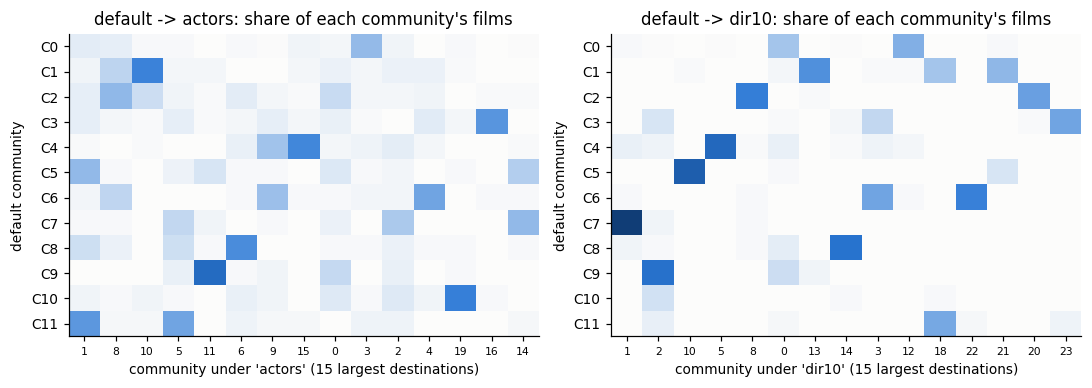

In [8]:
def comates(lab):
    return [set(np.flatnonzero(lab == lab[i])) - {i} for i in range(n)]
cm0 = comates(L0)
move = {}
for s in ct.SCHEMES[1:]:
    cms = comates(L[s])
    move[s] = np.array([len(a & b) / len(a | b) if a | b else 1.0 for a, b in zip(cm0, cms)])
move_df = pd.DataFrame({s: {"mean Jaccard of co-members": v.mean(), "films keeping >= 50% co-members": (v >= .5).mean()}
                        for s, v in move.items()}).T
move_df.to_csv(OUT / "film_movement.csv"); display(move_df)

top = np.arange(12)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, s in zip(axes, ["actors", "dir10"]):
    ct_tab = pd.crosstab(L0, L[s]).loc[top]
    keep = ct_tab.sum().sort_values(ascending=False).index[:15]
    frac = ct_tab[keep].div(ct_tab.sum(1), axis=0)
    ax.imshow(frac.to_numpy(), cmap=LinearSegmentedColormap.from_list("seq", ["#fcfcfb", "#2a78d6", "#0d366b"]), vmin=0, vmax=1, aspect="auto")
    ax.set_yticks(range(len(top)), [f"C{c}" for c in top]); ax.set_xticks(range(len(keep)), [f"{c}" for c in keep], fontsize=7)
    ax.set_xlabel(f"community under '{s}' (15 largest destinations)"); ax.set_ylabel("default community")
    ax.set_title(f"default -> {s}: share of each community's films")
fig.tight_layout(); fig.savefig(OUT / "film_movement.pdf"); plt.show()

## 4. A second clustering from the plots themselves

A *k*-nearest-neighbour graph (k = 10, symmetrised, weight = cosine similarity) built from each similarity
matrix, clustered with the same Louvain + consensus pipeline. These are **plot-based clusters**. NMI / AMI with the
collaboration communities says how much *who made the film* and *what the film is about* partition the films
alike; AMI corrects for chance (0 = independent labels). The same scores against primary genre give the reference
point.

In [9]:
PLOT = {}
for kind in SIMS:
    Gk = ct.knn_graph(S[kind], k=10)
    runs = ct.louvain_runs(Gk, range(20))
    PLOT[kind], _ = ct.consensus_partition(runs)
    print(f"kNN-{kind}: {len(np.unique(PLOT[kind]))} clusters, Q = {ct.modularity(Gk, PLOT[kind]):.3f}, "
          f"seed NMI = {ct.pairwise_scores(list(runs)).mean():.3f}")

refs = {"collaboration (default)": L0, "collaboration (actors)": L["actors"], "collaboration (dir10)": L["dir10"],
        "plot kNN (embed)": PLOT["embed"], "plot kNN (tfidf)": PLOT["tfidf"], "primary genre": PG}
rows = []
for a, b in [("plot kNN (embed)", "collaboration (default)"), ("plot kNN (tfidf)", "collaboration (default)"),
             ("plot kNN (embed)", "collaboration (actors)"), ("plot kNN (embed)", "collaboration (dir10)"),
             ("plot kNN (embed)", "plot kNN (tfidf)"),
             ("plot kNN (embed)", "primary genre"), ("collaboration (default)", "primary genre")]:
    rows.append({"partition A": a, "partition B": b, **ct.compare(refs[a], refs[b])})
second = pd.DataFrame(rows); second.to_csv(OUT / "second_clustering.csv", index=False)
pd.DataFrame({"node_id": nodes.node_id, "knn_embed": PLOT["embed"], "knn_tfidf": PLOT["tfidf"]}).to_csv(
    OUT / "plot_clusters.tsv", sep="\t", index=False)
second

kNN-tfidf: 23 clusters, Q = 0.554, seed NMI = 0.707


kNN-embed: 9 clusters, Q = 0.553, seed NMI = 0.676


,partition A,partition B,NMI,AMI,ARI
0,plot kNN (embed),collaboration (default),0.083,0.015,0.004
1,plot kNN (tfidf),collaboration (default),0.115,0.007,0.001
2,plot kNN (embed),collaboration (actors),0.099,0.013,0.005
3,plot kNN (embed),collaboration (dir10),0.092,0.019,0.004
4,plot kNN (embed),plot kNN (tfidf),0.280,0.264,0.213
5,plot kNN (embed),primary genre,0.256,0.241,0.152
6,collaboration (default),primary genre,0.126,0.023,0.004


## 5. Genre alignment (SQ4)

**Genre assortativity.** For each genre, the attribute assortativity of the binary label "film has genre *g*"
(Newman 2003) on the `default` network. Then: the share of edges whose films share at least one genre, compared
with A's 100 rewired networks (same degrees) and with all film pairs.

In [10]:
ga = ct.genre_assortativity(G["default"], nodes)
ga = ga[ga.films >= 20].sort_values("assortativity", ascending=False)
ga.to_csv(OUT / "genre_assortativity.csv", index=False)

ei = np.nonzero(np.triu(W0))
obs_share, obs_jac = ct.genre_overlap_of_edges(ei, nodes)
null_share = []
for k in range(N_REWIRED):
    e = nt.read_tsv(ROOT / "network" / "null" / f"rewired_{k}.tsv")
    null_share.append(ct.genre_overlap_of_edges(nt.edge_index(e, nodes), nodes))
null_share = np.array(null_share)
rng = np.random.default_rng(5)
ri, rj = rng.integers(0, n, 200_000), rng.integers(0, n, 200_000); keep = ri != rj
rand_share = ct.genre_overlap_of_edges((ri[keep], rj[keep]), nodes)
print(f"edges sharing >= 1 genre: {obs_share:.3f} (mean Jaccard {obs_jac:.3f}); rewired {null_share[:, 0].mean():.3f} "
      f"+- {null_share[:, 0].std(ddof=1):.3f} (z = {(obs_share - null_share[:, 0].mean()) / null_share[:, 0].std(ddof=1):.1f}); "
      f"random pairs {rand_share[0]:.3f}")
ga

edges sharing >= 1 genre: 0.752 (mean Jaccard 0.266); rewired 0.653 +- 0.004 (z = 25.2); random pairs 0.614


,genre,films,assortativity
3,Comedy,614,0.244
10,Horror,274,0.149
0,Action,472,0.147
6,Drama,1047,0.119
14,Romance,278,0.068
1,Adventure,269,0.057
13,Mystery,251,0.053
2,Biography,198,0.049
17,Thriller,331,0.040
7,Family,72,0.035


**Community × genre enrichment.** Multi-label: a film counts for each of its genres. Hypergeometric upper tail
(over-representation), Benjamini–Hochberg over the whole table. And the overall agreement of communities with
primary genre (NMI, AMI) against size-preserving label shuffles.

In [11]:
big = np.flatnonzero(np.bincount(L0) >= MIN_SIZE)
genres_shown = list(gcount[gcount >= 20].index)
enr = ct.genre_enrichment(L0, nodes, big, genres_shown)
enr.to_csv(OUT / "community_genre_enrichment.csv", index=False)
print(f"{len(big)} communities with >= {MIN_SIZE} films cover {np.isin(L0, big).mean():.0%} of films; "
      f"{(enr.q < 0.05).sum()} of {len(enr)} community-genre cells over-represented at q < 0.05")

rng = np.random.default_rng(6)
null_ami = np.array([AMI(rng.permutation(L0), PG) for _ in range(200)])
print(f"communities vs primary genre: NMI = {NMI(L0, PG):.3f}, AMI = {AMI(L0, PG):.3f} "
      f"(shuffled AMI {null_ami.mean():.4f} +- {null_ami.std(ddof=1):.4f})")

21 communities with >= 40 films cover 84% of films; 11 of 357 community-genre cells over-represented at q < 0.05


communities vs primary genre: NMI = 0.126, AMI = 0.023 (shuffled AMI -0.0003 +- 0.0030)


## 6. Beyond genre (SQ4)

If communities only re-discovered genres, two films of the *same genre* would be equally similar whether or not
they are in the same community. We compare four kinds of pairs: same/different primary genre ×
same/different community, on all pairs and on unlinked pairs only. The test statistic is the difference
same-genre-same-community − same-genre-different-community, against 999 size-preserving community-label
shuffles (genres stay fixed). Robustness: "same genre" = identical full IMDb genre set.

In [12]:
pairs = ct.pair_table(L0, nodes, W0, S, PG)
pairs["same_set"] = pairs.genre_jaccard == 1
ii, jj = pairs.i.to_numpy(), pairs.j.to_numpy()

def beyond_genre(genre_col, mask=None, n_perm=N_PERM, seed=7):
    m = np.ones(len(pairs), bool) if mask is None else mask
    sg = pairs[genre_col].to_numpy()[m]
    out = {}
    for kind in SIMS:
        v = pairs[kind].to_numpy()[m]
        def stat(lab):
            sc = lab[ii[m]] == lab[jj[m]]
            return v[sg & sc].mean() - v[sg & ~sc].mean(), sc
        obs, sc = stat(L0)
        rng = np.random.default_rng(seed)
        null = np.array([stat(rng.permutation(L0))[0] for _ in range(n_perm)])
        cell = lambda g, c: v[(sg == g) & (sc == c)].mean()
        out[kind] = {"same genre, same comm.": cell(True, True), "same genre, diff. comm.": cell(True, False),
                     "diff. genre, same comm.": cell(False, True), "diff. genre, diff. comm.": cell(False, False),
                     "n same genre, same comm.": int((sg & sc).sum()),
                     "diff (SG-SC minus SG-DC)": obs, "z": (obs - null.mean()) / null.std(ddof=1),
                     "p": (1 + (null >= obs).sum()) / (n_perm + 1)}
    return pd.DataFrame(out).T

bg = pd.concat({"primary genre, all pairs": beyond_genre("same_primary"),
                "primary genre, unlinked pairs": beyond_genre("same_primary", ~pairs.linked.to_numpy()),
                "same genre set, all pairs": beyond_genre("same_set")})
bg.to_csv(OUT / "beyond_genre.csv"); bg

same genre, same comm.  same genre, diff. comm.  diff. genre, same comm.  diff. genre, diff. comm.  \
primary genre, all pairs      tfidf                   0.039                    0.038                    0.028                     0.028   
                              embed                   0.669                    0.666                    0.608                     0.607   
primary genre, unlinked pairs tfidf                   0.038                    0.038                    0.028                     0.028   
                              embed                   0.667                    0.666                    0.606                     0.607   
same genre set, all pairs     tfidf                   0.046                    0.044                    0.029                     0.028   
                              embed                   0.692                    0.691                    0.611                     0.610   

                                     n same genre, same comm.  diff (SG-SC minus SG-DC)      z      p  
primary genre, all pairs      tfidf                    4631.0                 9.619e-04  1.793  0.035  
                              embed                    4631.0                 2.843e-03  1.107  0.133  
primary genre, unlinked pairs tfidf                    3958.0                 4.248e-04  0.789  0.218  
                              embed                    3958.0                 1.275e-03  0.513  0.300  
same genre set, all pairs     tfidf                    1118.0                 2.663e-03  2.397  0.008  
                              embed                    1118.0                 5.663e-04  0.160  0.433

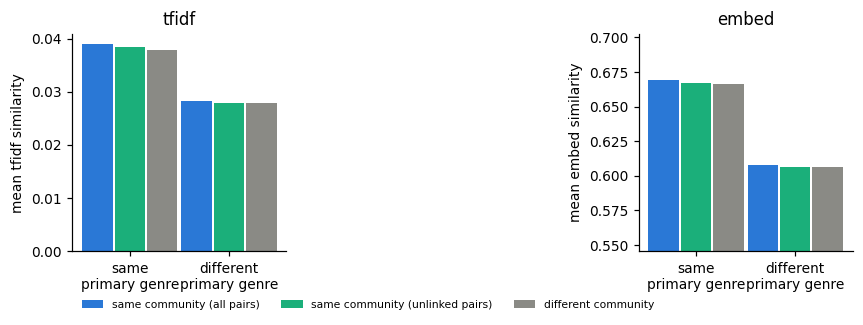

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.1), sharey=False)
for ax, kind in zip(axes, SIMS):
    r = bg.loc["primary genre, all pairs"].loc[kind]
    ru = bg.loc["primary genre, unlinked pairs"].loc[kind]
    x = np.arange(2)
    for k, (rr, lab, col) in enumerate([(r, "all pairs", C1), (ru, "unlinked pairs", C3)]):
        ax.bar(x * 2.6 + k * 0.85, [rr["same genre, same comm."], rr["diff. genre, same comm."]], 0.8, color=col, label=f"same community ({lab})")
    ax.bar(x * 2.6 + 1.7, [r["same genre, diff. comm."], r["diff. genre, diff. comm."]], 0.8, color=C_NULL, label="different community")
    ax.set_xticks(x * 2.6 + 0.85, ["same\nprimary genre", "different\nprimary genre"])
    ax.set_ylabel(f"mean {kind} similarity"); ax.set_title(kind)
    lo = min(r["diff. genre, diff. comm."], ru["diff. genre, same comm."]); ax.set_ylim(lo * 0.9 if kind == "embed" else 0)
axes[0].legend(frameon=False, fontsize=7, ncol=3, loc="upper left", bbox_to_anchor=(0, -0.18))
fig.tight_layout(); fig.savefig(OUT / "beyond_genre.pdf", bbox_inches="tight"); plt.show()

**Qualitative examples.** The most plot-similar pairs inside one community whose films share **no** IMDb genre
(genre Jaccard = 0), at most two pairs per community. Read these for the paper: do they share a theme the genre
labels miss, or a person (the edge)?

In [14]:
E = nt.load_edges()
key = lambda a, b: tuple(sorted((a, b)))
people = {key(r.source, r.target): ", ".join(x for x in [r.director_names, r.actor_names, r.cross_names] if isinstance(x, str) and x)
          for r in E.itertuples()}
cand = pairs[pairs.same_comm & (pairs.genre_jaccard == 0)].sort_values("embed", ascending=False)
cand = cand.assign(community=L0[cand.i]).groupby("community").head(2).head(20)
ex = pd.DataFrame({"community": cand.community.to_numpy(),
                   "film A": [f"{title[i]} ({nodes.year[i]})" for i in cand.i], "genres A": nodes.genres.to_numpy()[cand.i],
                   "film B": [f"{title[j]} ({nodes.year[j]})" for j in cand.j], "genres B": nodes.genres.to_numpy()[cand.j],
                   "embed": cand.embed.round(3).to_numpy(), "tfidf": cand.tfidf.round(3).to_numpy(),
                   "embed pct": (stats.percentileofscore(pairs.embed, cand.embed) ).round(2),
                   "shared people (if linked)": [people.get(key(nodes.node_id[i], nodes.node_id[j]), "-") for i, j in zip(cand.i, cand.j)],
                   "plot A": nodes.description.to_numpy()[cand.i], "plot B": nodes.description.to_numpy()[cand.j]})
ex.to_csv(OUT / "cross_genre_pairs.tsv", sep="\t", index=False)
with pd.option_context("display.max_colwidth", 120):
    display(ex.drop(columns=["plot A", "plot B"]))
for r in ex.head(6).itertuples():
    print(f"\n[C{r.community}] {r._2}  <->  {r._4}   (embed {r.embed}, top {100 - r._8:.2f}% of pairs)\n  A: {r._10}\n  B: {r._11}")

,community,film A,genres A,film B,genres B,embed,tfidf,embed pct,shared people (if linked)
0,6,21 & Over (2013),Comedy,The Spectacular Now (2013),"Drama,Romance",0.902,0.074,99.99,Miles Teller
1,10,No Good Deed (2014),"Crime,Drama,Horror",Peppermint (2018),"Action,Thriller",0.902,0.079,99.99,-
2,10,Peppermint (2018),"Action,Thriller",The Lincoln Lawyer (2011),"Crime,Drama,Mystery",0.899,0.093,99.98,-
3,21,Bad Samaritan (2018),"Crime,Drama,Horror",The Bounty Hunter (2010),"Action,Comedy,Romance",0.890,0.051,99.96,-
4,0,Hick (2011),"Comedy,Drama",The Prodigy (2019),"Fantasy,Horror,Mystery",0.889,0.026,99.96,-
5,1,"Love, Rosie (2014)","Comedy,Romance",Welcome to the Rileys (2010),Drama,0.885,0.065,99.95,-
6,6,Ma (2019),"Horror,Mystery,Thriller",The Spectacular Now (2013),"Drama,Romance",0.884,0.086,99.94,-
7,20,In Your Eyes (2014),"Fantasy,Romance",Ingrid Goes West (2017),"Comedy,Drama,Horror",0.883,0.069,99.93,-
8,11,Jack Reacher (2012),"Action,Thriller",The Killer Inside Me (2010),"Crime,Drama,Mystery",0.879,0.085,99.92,-
9,15,Come to Daddy (2019),"Comedy,Mystery,Thriller",The Frozen Ground (2013),"Biography,Crime,Drama",0.878,0.063,99.91,-



[C6] 21 & Over (2013)  <->  The Spectacular Now (2013)   (embed 0.902, top 0.01% of pairs)
  A: Casey and Miller invite their college friend, Jeff Chang, out to celebrate his 21st birthday.
  B: Sutter Keely is a charming and popular 18-year-old who has spent his senior year of high school partying and drinking alcohol.

[C10] No Good Deed (2014)  <->  Peppermint (2018)   (embed 0.902, top 0.01% of pairs)
  A: Colin Evans has been sentenced to prison for 15 years for manslaughter in the state of Tennessee.
  B: A woman is engaged in a brutal fight with a man in a car and finally kills him with a shot to the head.

[C10] Peppermint (2018)  <->  The Lincoln Lawyer (2011)   (embed 0.899, top 0.02% of pairs)
  A: A woman is engaged in a brutal fight with a man in a car and finally kills him with a shot to the head.
  B: Criminal defense attorney Mickey Haller works in Los Angeles County, California, from the back of his black Lincoln Town Car, chauffeured by Earl Briggs.

[C21] Bad Samari

## 7. Characterizing the communities

B's `distinctive_words` (weighted log-odds with an informative Dirichlet prior, Monroe et al. 2008; each community
against all other films) and the LDA topic shares (coherent topics only): mean share in the community divided by
the mean share over all films (lift).

In [15]:
dw = distinctive_words(dict(zip(nodes.node_id, L0)), top_n=10)
dw.to_csv(OUT / "distinctive_words_default.tsv", sep="\t", index=False)
WORDS = dw.groupby("group").word.apply(list)

topics = pd.read_csv(ROOT / "nlp" / "topics" / "topics.tsv", sep="\t").set_index("node_id").loc[nodes.node_id]
tlab = pd.read_csv(ROOT / "nlp" / "topics" / "topic_labels.tsv", sep="\t")
coherent = tlab[tlab.coherent].topic.to_list()
T = topics[[f"topic_{t}" for t in coherent]].to_numpy()
lift = pd.DataFrame([T[L0 == c].mean(0) / T.mean(0) for c in big], index=big, columns=coherent)

rows = []
votes = nodes.num_votes.to_numpy()
for c in big:
    m = L0 == c
    idx = np.flatnonzero(m)
    sub = W0[np.ix_(m, m)]
    e_in = (sub > 0).sum() / 2
    strength_in, strength = sub.sum(), W0[m].sum()
    within = {k: S[k][np.ix_(m, m)][np.triu_indices(m.sum(), 1)].mean() for k in SIMS}
    e = enr[(enr.community == c) & (enr.q < 0.05)].sort_values("log2_enrich", ascending=False)
    tl = lift.loc[c].sort_values(ascending=False)
    rows.append({"community": c, "films": int(m.sum()), "internal edges": int(e_in),
                 "density": e_in / (m.sum() * (m.sum() - 1) / 2), "strength inside": strength_in / strength,
                 "within embed": within["embed"], "within tfidf": within["tfidf"],
                 "median year": int(np.median(nodes.year[m])),
                 "enriched genres": ", ".join(e.genre.head(3)) or "-",
                 "top topics (lift)": "; ".join(f"{tlab.label[t]} ({tl[t]:.1f})" for t in tl.index[:2]),
                 "distinctive words": ", ".join(WORDS.get(c, [])[:6]),
                 "best-known films": "; ".join(title[idx[np.argsort(-votes[idx])[:3]]])})
cstats = pd.DataFrame(rows).set_index("community")
cstats = pd.concat([cstats, pd.DataFrame([{"films": n, "within embed": S["embed"][iu].mean(), "within tfidf": S["tfidf"][iu].mean()}],
                                          index=pd.Index(["all films"], name="community"))])
cstats.to_csv(OUT / "community_table.csv")
cstats[["films", "density", "strength inside", "within embed", "within tfidf", "median year", "enriched genres", "distinctive words",
        "best-known films"]].to_latex(OUT / "community_table.tex", float_format="%.3g")
with pd.option_context("display.max_colwidth", 70):
    display(cstats)

,films,internal edges,density,strength inside,within embed,within tfidf,median year,enriched genres,top topics (lift),distinctive words,best-known films
community,,,,,,,,,,,
0,130,484.0,0.058,0.537,0.613,0.029,2014.0,-,"spies, military and terrorism (1.4); ghosts, possession and the su...","israel, gunman, pope, israeli, oxford, patient",Shutter Island; Deadpool; Prisoners
1,100,381.0,0.077,0.584,0.596,0.027,2015.0,-,"writers, books and hotels (2.1); fantasy: kings, battles and witch...","queen, giant, painting, dwarf, cow, slave",Mad Max: Fury Road; Bohemian Rhapsody; Pirates of the Caribbean: O...
2,97,413.0,0.089,0.537,0.590,0.028,2014.0,Drama,"writers, books and hotels (1.7); money and business (1.7)","whip, orlando, emperor, rat, england, auto",The Martian; Black Swan; 12 Years a Slave
3,93,247.0,0.058,0.587,0.637,0.030,2015.0,Comedy,"music, bands and performing (1.3); relationships and family life (...","bolt, spring, list, sorority, santa, cake",Harry Potter and the Deathly Hallows – Part 2; Horrible Bosses; El...
4,88,432.0,0.113,0.620,0.599,0.027,2013.0,-,"music, bands and performing (1.8); competition: sports, jobs and c...","stadium, bus, mafia, senator, retirement, fbi",Joker; The Hunger Games; Man of Steel
5,80,297.0,0.094,0.620,0.644,0.030,2015.0,-,"writers, books and hotels (1.8); film industry and journalism (1.4)","voice, purge, cia, attic, box, christian",Her; Midsommar; Jojo Rabbit
6,75,241.0,0.087,0.568,0.572,0.027,2015.0,Biography,sea and survival (2.4); film industry and journalism (1.8),"lady, expedition, book, american, portal, writer",Whiplash; Oblivion; Rush
7,72,258.0,0.101,0.609,0.652,0.031,2014.0,-,"crime: police, drugs and gangs (1.7); spies, military and terroris...","hockey, pig, agent, map, list, ice",The Avengers; The Grand Budapest Hotel; Knives Out
8,71,244.0,0.098,0.535,0.637,0.030,2015.0,-,"family survival: war, farms, camps (1.5); sea and survival (1.4)","church, tank, counselor, cartel, kid, farmer",The Revenant; The Great Gatsby; Fury


## 8. Fig. 3: community × genre, with each community's distinctive words

Rows: the consensus communities of the `default` network with at least 40 films, ordered by hierarchical
clustering of their genre profiles (so communities with similar genre mixes sit together). Columns: IMDb genres
with ≥ 20 films. Colour: log2 of observed / expected films of that genre in the community (red = more than
expected). Dot: over-represented at BH q < 0.05 (hypergeometric). Right: the community's six most distinctive plot
words and its mean within-community embedding similarity relative to all films.

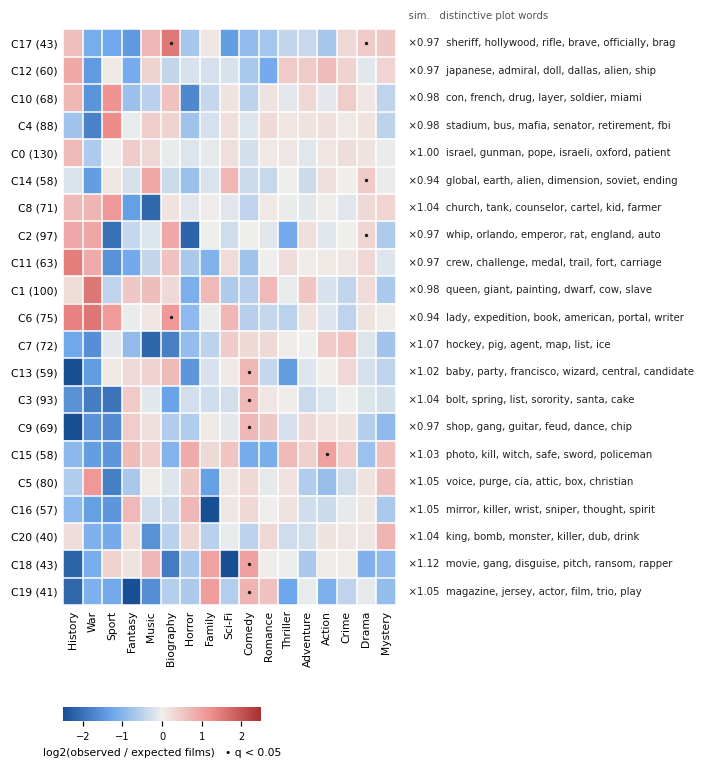

In [16]:
from scipy.cluster.hierarchy import linkage, leaves_list
M = enr.pivot(index="community", columns="genre", values="log2_enrich").loc[big, genres_shown]
Q = enr.pivot(index="community", columns="genre", values="q").loc[big, genres_shown]
row_order = M.index[leaves_list(linkage(M.to_numpy(), "average", metric="euclidean"))]
col_order = M.columns[leaves_list(linkage(M.to_numpy().T, "average", metric="euclidean"))]
M, Q = M.loc[row_order, col_order], Q.loc[row_order, col_order]
base_embed = S["embed"][iu].mean()

fig = plt.figure(figsize=(7.2, 0.27 * len(M) + 1.6))
ax = fig.add_axes([0.09, 0.2, 0.42, 0.72])
im = ax.imshow(M.clip(-2.5, 2.5).to_numpy(), cmap=DIVERGING, norm=TwoSlopeNorm(0, -2.5, 2.5), aspect="auto")
yy, xx = np.nonzero(Q.to_numpy() < 0.05)
ax.scatter(xx, yy, s=5, color="#1a1a19", linewidths=0)
ax.set_xticks(range(M.shape[1]), M.columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(M)), [f"C{c} ({(L0 == c).sum()})" for c in M.index], fontsize=7)
ax.tick_params(length=0)
for sp in ax.spines.values(): sp.set_visible(False)
ax.set_xticks(np.arange(M.shape[1] + 1) - .5, minor=True); ax.set_yticks(np.arange(len(M) + 1) - .5, minor=True)
ax.grid(which="minor", color="white", lw=1); ax.tick_params(which="minor", length=0)
for k, c in enumerate(M.index):
    rel = cstats.loc[c, "within embed"] / base_embed
    ax.text(M.shape[1] - 0.2, k, f"  ×{rel:.2f}  " + ", ".join(WORDS.get(c, [])[:6]), va="center", ha="left", fontsize=6.6, color="#222")
ax.text(M.shape[1] - 0.2, -1.0, "  sim.   distinctive plot words", fontsize=6.6, color="#555", va="center")
cax = fig.add_axes([0.09, 0.055, 0.25, 0.018])
cb = fig.colorbar(im, cax=cax, orientation="horizontal"); cb.outline.set_visible(False)
cb.set_label("log2(observed / expected films)   • q < 0.05", fontsize=7); cb.ax.tick_params(labelsize=6.5)
fig.savefig(OUT / "fig3_community_genre.pdf", bbox_inches="tight"); fig.savefig(OUT / "fig3_community_genre.png", dpi=200, bbox_inches="tight")
plt.show()

## 9. Key numbers for the paper

In [17]:
emb = coh.set_index(["similarity", "pairs"])
bge = bg.loc["primary genre, all pairs"].loc["embed"]; bgu = bg.loc["primary genre, unlinked pairs"].loc["embed"]
sec = second.set_index(["partition A", "partition B"])
lines = [
    f"Louvain (default): {stab.loc['default', 'communities >= 5 films']} communities of >= 5 films, Q = {q_obs:.3f} "
    f"(rewired {q_null.mean():.3f} +- {q_null.std(ddof=1):.3f}, z = {z_q:.0f}); seed stability NMI = {stab.loc['default', 'NMI seeds mean']:.2f}",
    *[f"coherence {k}: within {emb.loc[(k, 'all'), 'within']:.3f} vs between {emb.loc[(k, 'all'), 'between']:.3f} "
      f"(x{emb.loc[(k, 'all'), 'ratio within/between']:.2f}, z = {emb.loc[(k, 'all'), 'z']:.0f}); unlinked pairs only "
      f"x{emb.loc[(k, 'unlinked only'), 'ratio within/between']:.2f}, z = {emb.loc[(k, 'unlinked only'), 'z']:.0f}" for k in SIMS],
    f"silhouette embed {sil.set_index('similarity').loc['embed', 'silhouette']:.3f} (null {sil.set_index('similarity').loc['embed', 'null mean']:.3f})",
    f"most coherent scheme (embed z): {coh_s[coh_s.similarity == 'embed'].set_index('scheme').z.idxmax()}",
    f"plot kNN vs collaboration: AMI = {sec.loc[('plot kNN (embed)', 'collaboration (default)'), 'AMI']:.3f}; "
    f"plot kNN vs genre AMI = {sec.loc[('plot kNN (embed)', 'primary genre'), 'AMI']:.3f}; "
    f"collaboration vs genre AMI = {sec.loc[('collaboration (default)', 'primary genre'), 'AMI']:.3f}",
    f"edges sharing a genre: {obs_share:.2f} vs rewired {null_share[:, 0].mean():.2f} vs random {rand_share[0]:.2f}",
    f"beyond genre (embed): same genre same comm {bge['same genre, same comm.']:.3f} vs same genre diff comm "
    f"{bge['same genre, diff. comm.']:.3f} (z = {bge['z']:.0f}); unlinked z = {bgu['z']:.0f}",
]
(OUT / "key_numbers.txt").write_text("\n".join(lines) + "\n")
print("\n".join(lines))

Louvain (default): 31 communities of >= 5 films, Q = 0.530 (rewired 0.300 +- 0.002, z = 151); seed stability NMI = 0.67
coherence tfidf: within 0.029 vs between 0.029 (x1.02, z = 3); unlinked pairs only x1.01, z = 1
coherence embed: within 0.613 vs between 0.611 (x1.00, z = 1); unlinked pairs only x1.00, z = -0
silhouette embed -0.106 (null -0.107)
most coherent scheme (embed z): directors
plot kNN vs collaboration: AMI = 0.015; plot kNN vs genre AMI = 0.241; collaboration vs genre AMI = 0.023
edges sharing a genre: 0.75 vs rewired 0.65 vs random 0.61
beyond genre (embed): same genre same comm 0.669 vs same genre diff comm 0.666 (z = 1); unlinked z = 1


## 10. Findings (for Results SQ3/SQ4 and the Discussion)

All numbers come from `results/communities/`. Seeds are fixed, so a rerun gives the same values.

**SQ3: communities exist, but they are not plot communities.**
* The collaboration network has clear community structure: Q = 0.53 vs. 0.30 ± 0.002 in A's degree-preserving
  rewired networks (z ≈ 150). Partitions are moderately stable across seeds (mean pairwise NMI 0.67; the consensus
  partition agrees with single runs at NMI 0.75). Director-heavy weightings are more stable (dir10: 0.79).
* Plot similarity inside communities is barely above that between communities: TF-IDF ×1.02 (z ≈ 3, p = 0.001),
  embeddings ×1.003 (z ≈ 1, n.s.). Restricted to *unlinked* pairs, the difference disappears for both. Silhouettes
  equal their shuffled nulls. A's edge-level signal (linked pairs 0.629 vs. unlinked 0.611, embeddings) is local:
  about 90 % of within-community pairs are not linked, and they are no more similar than random pairs.
* Across schemes, *directors only* gives by far the most plot-coherent groups (z ≈ 8 embeddings, ≈ 13 TF-IDF):
  films by the same director tell similar stories. Mixing directors into the actor network raises coherence from
  actors-only, but there is no monotone gain with director weight. Partitions differ a lot between schemes
  (NMI 0.45–0.79, ARI mostly < 0.4), so which films are grouped depends strongly on the weighting.
* A second clustering built from the plots themselves (k-NN graph of embeddings) is almost independent of the
  collaboration communities (AMI 0.015) but matches genre (AMI 0.24).

**SQ4: genre shows up at the edge level, not as narrative themes beyond genre.**
* Collaboration is genre-assortative: 75 % of edges join films sharing a genre, vs. 65 % in rewired networks and
  61 % for random pairs; per-genre assortativity is highest for Comedy (0.24), Horror and Action (0.15) (typecasting).
* At the community level genre alignment is weak (NMI with primary genre 0.13, AMI 0.02). Only a few community ×
  genre cells are significantly enriched (mostly Comedy, plus Biography, Drama and Action): Fig. 3.
* Beyond genre: two films of the same primary genre are not more similar when they share a community
  (embeddings 0.669 vs. 0.666, z ≈ 1; unlinked pairs z ≈ 0.5). The genre effect (0.67 vs. 0.61) is far larger than
  the community effect. The distinctive words of communities are mostly unrelated words, consistent with this.
* The qualitative cross-genre pairs (`cross_genre_pairs.tsv`) are very plot-similar (top 0.1 % of pairs) but
  mostly *not* linked. They share story templates (coming of age, revenge, home invasion) that the IMDb labels
  split, but they sit in the same community by chance more often than through a shared person. Read them as
  examples of what genre labels miss, not as evidence that communities find themes.

**Caveats.** Louvain at resolution 1 only; primary genre = rarest listed genre (IMDb lists genres alphabetically);
genre-enrichment colours for genres with few expected films are noisy (pseudocount 0.5).